# 08 · Comparación final y discusión (Cisco)

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "data.py").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Ejecutar desde el repositorio DL-LAB09")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from src import data as D, metrics as M, backtest as B
RUN_TRAIN = False  # Cambiar a True solo para generar artefactos que falten.


In [2]:
display(pd.read_csv(ROOT/"outputs"/"tables"/"comparacion.csv"))
display(pd.read_csv(ROOT/"outputs"/"tables"/"probabilistica.csv"))
display(pd.read_csv(ROOT/"outputs"/"tables"/"navidad.csv").sort_values("MASE"))

,modelo,hardware,inference_s,familia,L,estrategia,covariables,train_s,model_id,load_s,...,hidden,epochs,max_batches_per_epoch,train_s_search_total,train_s_criterio,arboles,seleccion,params_referencia,nota,pasos
0,iTransformer,NVIDIA GeForce RTX 5070 Laptop GPU,16.308844,Atención,168,multi-salida,False,75.655578,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ChronosBolt,CPU (AMD Ryzen AI 7 350 w/ Radeon 860M),84.806595,Fundacional,168,zero-shot,False,0.000000,amazon/chronos-bolt-small,2.890486,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,MLP,NVIDIA GeForce RTX 5070 Laptop GPU,13.741018,MLP y lineales,168,multi-salida,True,164.607207,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LightGBM,NVIDIA GeForce RTX 5070 Laptop GPU,24.734162,Árboles,168,recursiva,True,48.247824,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,600.0,NaN,NaN,NaN,NaN
4,PatchTST,NVIDIA GeForce RTX 5070 Laptop GPU,17.175391,Atención,168,multi-salida,False,148.286248,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NLinear,NVIDIA GeForce RTX 5070 Laptop GPU,18.147093,MLP y lineales,168,multi-salida,False,172.414684,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,DLinear,NVIDIA GeForce RTX 5070 Laptop GPU,14.470438,MLP y lineales,168,multi-salida,False,77.410107,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,MSTL,NVIDIA GeForce RTX 5070 Laptop GPU,434.966248,Baseline (estadístico),1344,directa (modelo de estado),False,0.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,se reajusta por cliente en cada origen; el tie...,NaN
8,SeasonalNaive24,NVIDIA GeForce RTX 5070 Laptop GPU,13.162872,Baseline,24,directa (copia),False,0.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,SeasonalNaive168,NVIDIA GeForce RTX 5070 Laptop GPU,13.785666,Baseline,168,directa (copia),False,0.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,modelo,pinball_q10,pinball_q50,pinball_q90,pinball,cobertura_P10_P90
0,ChronosBolt,14.289627,28.597483,14.023352,18.970154,0.812014
1,DeepAR,36.769054,92.275050,47.472543,58.838882,0.711941


,modelo,MAE,RMSE,WAPE,MAPE,MAPE_excluidas,MASE,n,pinball_q10,pinball_q50,pinball_q90,pinball,cobertura_P10_P90
0,iTransformer,76.409066,498.543985,0.114835,0.199215,377,1.386156,25200,NaN,NaN,NaN,NaN,NaN
1,ChronosBolt,87.164673,575.908630,0.131000,0.180033,377,1.485922,25200,35.158493,43.582336,18.103628,32.281487,0.721468
2,MLP,87.401617,531.094721,0.131356,0.192074,377,1.505720,25200,NaN,NaN,NaN,NaN,NaN
3,LightGBM,92.915579,587.891006,0.139643,0.217239,377,1.578303,25200,NaN,NaN,NaN,NaN,NaN
4,PatchTST,95.164885,587.828476,0.143023,0.230770,377,1.659568,25200,NaN,NaN,NaN,NaN,NaN
9,SeasonalNaive168,84.746246,605.726501,0.127365,0.272050,377,1.661288,25200,NaN,NaN,NaN,NaN,NaN
6,DLinear,103.025483,616.458013,0.154837,0.251461,377,1.825051,25200,NaN,NaN,NaN,NaN,NaN
5,NLinear,102.675410,616.740858,0.154311,0.252489,377,1.826556,25200,NaN,NaN,NaN,NaN,NaN
10,TCN,111.819119,670.092555,0.168053,0.304217,377,1.970701,25200,NaN,NaN,NaN,NaN,NaN
7,MSTL,117.032730,668.793884,0.175888,0.310230,377,2.066476,25200,NaN,NaN,NaN,NaN,NaN


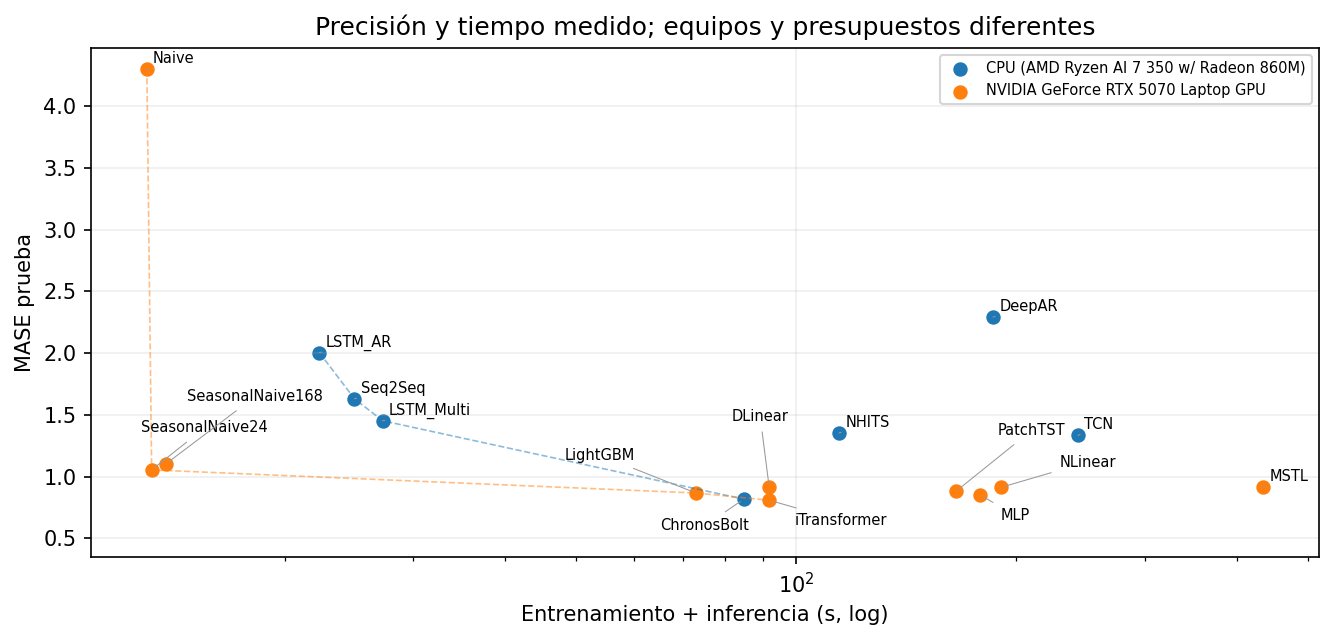

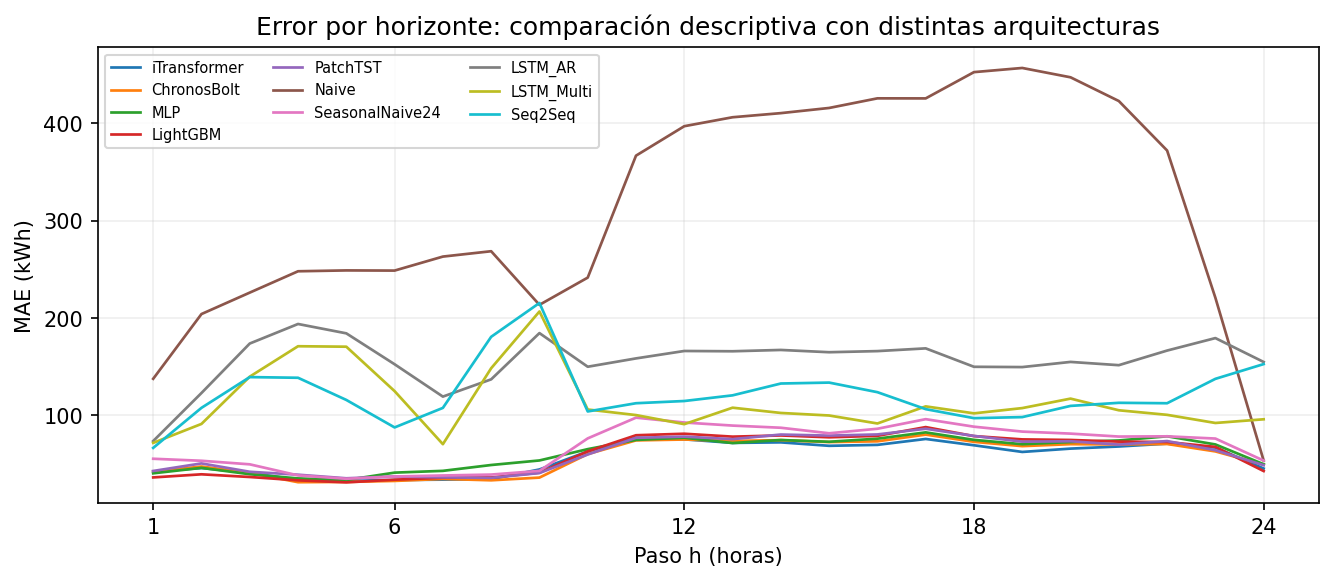

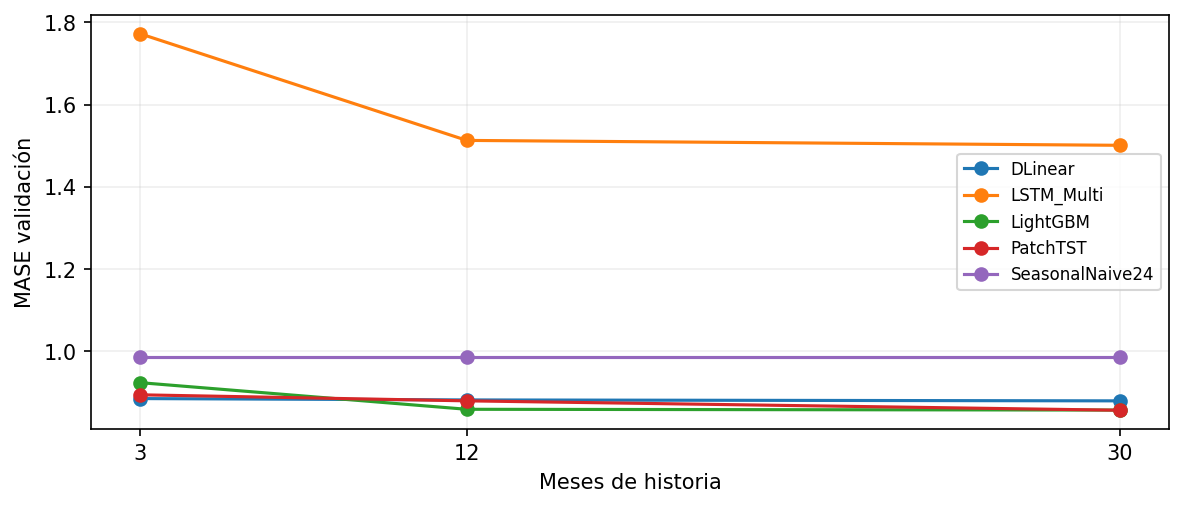

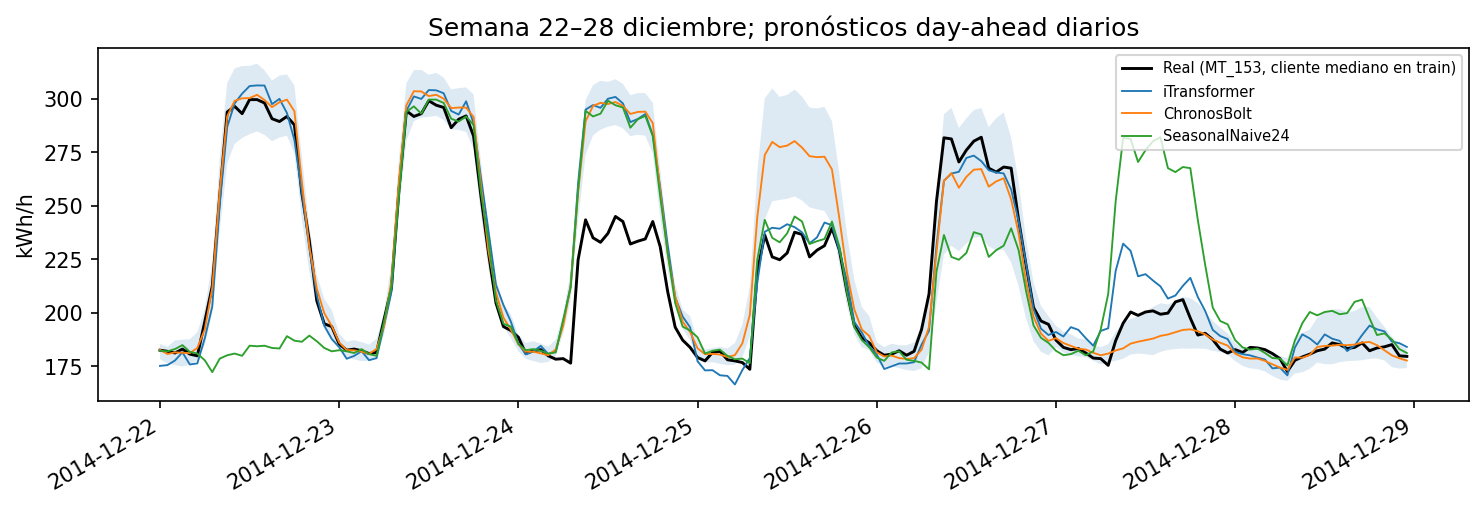

In [3]:
for name in ["pareto","mae_por_h","mase_vs_historia","semana_navidad_comparacion"]:
    display(Image(filename=str(ROOT/"outputs"/"figs"/f"{name}.png")))

Los tiempos de RTX 5070 y CPU reflejan equipos y presupuestos distintos. La clasificación de prueba es descriptiva; ninguna configuración se eligió con esas métricas. Ver `informe/informe.pdf` para discusión y limitaciones.